# Auditoría por subgrupos

Food-101 no contiene personas, así que los subgrupos relevantes son **condiciones de captura** que cambian entre usuarios reales: iluminación, temperatura de color (luz cálida de restaurante vs. luz fría) y nitidez. También se audita **por platillo** y, si existe, por **origen** en el conjunto del equipo (comida real / pantalla / impreso).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import *
sns.set_theme(style="whitegrid")
FIG_DIR.mkdir(parents=True, exist_ok=True)
ARCH = DEFAULT_ARCH

In [2]:
from sklearn.metrics import f1_score
from src.subgroups import image_attributes, add_subgroups
pred = pd.read_csv(RUNS_DIR / ARCH / "eval_test" / "predictions.csv")
attrs = image_attributes(pred.path)
df = add_subgroups(pred.merge(attrs, on="path"))
df["acierto"] = df.label == df.pred

def audit(col):
    g = df.groupby(col, observed=True)
    return pd.DataFrame({
        "n": g.size(),
        "exactitud": g.acierto.mean(),
        "f1_macro": g.apply(lambda d: f1_score(d.label, d.pred, average="macro")),
        "confianza_media": g.conf.mean(),
    }).round(3)

In [3]:
res = {c: audit(c) for c in ("iluminacion", "temperatura", "nitidez_grupo")}
for c, t in res.items():
    print(f"\n== {c} ==  (brecha máx-mín F1: {t.f1_macro.max() - t.f1_macro.min():.3f})"); display(t)


== iluminacion ==  (brecha máx-mín F1: 0.012)


/tmp/ipykernel_13822/3295410454.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "f1_macro": g.apply(lambda d: f1_score(d.label, d.pred, average="macro")),
/tmp/ipykernel_13822/3295410454.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "f1_macro": g.apply(lambda d: f1_score(d.label, d.pred, average="macro")),
/tmp/ipykernel_13822/3295410454.py:13: DeprecationWarning: DataFrameGroupBy.apply operated

,n,exactitud,f1_macro,confianza_media
iluminacion,,,,
oscura,791,0.858,0.850,0.775
media,792,0.851,0.856,0.757
clara,791,0.857,0.862,0.771



== temperatura ==  (brecha máx-mín F1: 0.026)


,n,exactitud,f1_macro,confianza_media
temperatura,,,,
fría,791,0.845,0.843,0.766
neutra,792,0.851,0.851,0.772
cálida,791,0.871,0.869,0.765



== nitidez_grupo ==  (brecha máx-mín F1: 0.011)


,n,exactitud,f1_macro,confianza_media
nitidez_grupo,,,,
borrosa,791,0.858,0.857,0.771
media,791,0.860,0.861,0.774
nítida,792,0.848,0.850,0.758


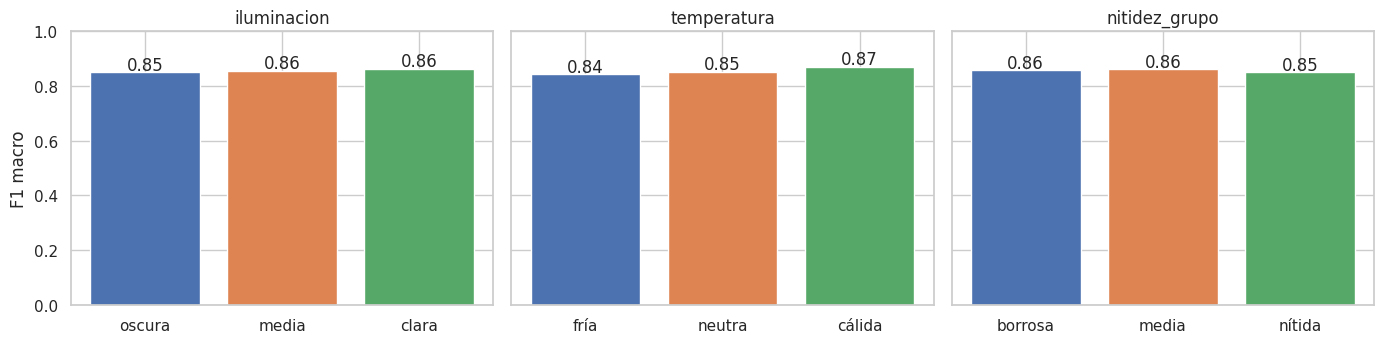

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (c, t) in zip(axes, res.items()):
    ax.bar(t.index.astype(str), t.f1_macro, color=sns.color_palette()[:len(t)])
    for i, v in enumerate(t.f1_macro): ax.text(i, v + 0.01, f"{v:.2f}", ha="center")
    ax.set_title(c); ax.set_ylim(0, 1)
axes[0].set_ylabel("F1 macro")
plt.tight_layout(); plt.savefig(FIG_DIR / "auditoria_subgrupos.png", dpi=120); plt.show()

## Por platillo (recall = qué tanto se detecta cada uno)

In [5]:
per = df.groupby("label").agg(n=("acierto", "size"), recall=("acierto", "mean"), confianza=("conf", "mean")).round(3)
per.index = per.index.map(DISPLAY); per.sort_values("recall")

,n,recall,confianza
label,,,
Otro platillo,374,0.727,0.675
Burrito,250,0.816,0.744
Huevos rancheros,250,0.832,0.745
Nachos,250,0.848,0.749
Tacos,250,0.868,0.781
Ceviche,250,0.876,0.775
Quesadilla,250,0.880,0.802
Guacamole,250,0.948,0.844
Churros,250,0.968,0.840


## Por origen de la foto (conjunto del equipo)

In [6]:
ood_pred = RUNS_DIR / ARCH / "eval_ood" / "predictions.csv"
if ood_pred.exists():
    od = pd.read_csv(ood_pred); od["acierto"] = od.label == od.pred
    display(od.groupby(["origen", "luz"]).agg(n=("acierto", "size"), exactitud=("acierto", "mean")).round(3))
else:
    print("Sin datos OOD todavía (ver eval/robustez.ipynb).")

,,n,exactitud
origen,luz,,
food500_web,desconocida,80,0.75


**Hallazgos y mitigación:** ver `docs/informe_etico.md` (sección Sesgos). La mitigación concreta implementada es el **umbral de confianza** con respuesta "No estoy seguro" en la app, más aumento de datos de color/brillo en entrenamiento.